# ResNet training comparison

讀取 `./outputs_pretrained` 與 `./outputs_scratch` 下的 ResNet18／50／101 `history.csv`。
每張圖包含六條曲線，分開顯示與保存 Train Accuracy、Train F1、Validation Accuracy、Validation F1。
同模型同顏色；pretrained 實線、scratch 虛線。請從兩個 outputs 資料夾所在位置執行 Notebook，或修改下方路徑。


In [8]:
# 若尚未安裝，取消下一行註解後執行
# %pip install pandas matplotlib

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from matplotlib.lines import Line2D

ROOTS = {
    "Pretrained": Path("./outputs_pretrained"),
    "Scratch": Path("./outputs_scratch"),
}
MODELS = ["resnet18", "resnet50", "resnet101"]
COLORS = {"resnet18": "#0072B2", "resnet50": "#D55E00", "resnet101": "#009E73"}
LINESTYLES = {"Pretrained": "-", "Scratch": "--"}
FIGURE_DIR = Path("./comparison_figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FIGURES = True
Y_LIMITS = (0.5, 1.01)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.titlesize": 23,
    "axes.titleweight": "bold",
    "axes.labelsize": 19,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.1,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

In [9]:
# 一次讀取六份 history，保留每個實驗自己的 epoch
REQUIRED = ["epoch", "train_accuracy", "train_f1", "val_accuracy", "val_f1"]
histories = {}
summary = []
for model in MODELS:
    for setting, root in ROOTS.items():
        path = root / model / "history.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Missing history: {path.resolve()}")
        df = pd.read_csv(path)
        missing = set(REQUIRED) - set(df.columns)
        if missing:
            raise ValueError(f"{path}: missing columns {sorted(missing)}; found {list(df.columns)}")
        df = df[REQUIRED].apply(pd.to_numeric, errors="raise").sort_values("epoch")
        if df.empty or df.isna().any().any() or df["epoch"].duplicated().any():
            raise ValueError(f"{path}: empty history, missing values, or duplicate epochs")
        if not ((df["epoch"] >= 1) & (df["epoch"] % 1 == 0)).all():
            raise ValueError(f"{path}: epochs must be positive integers")
        for column in REQUIRED[1:]:
            if not df[column].between(0, 1).all():
                raise ValueError(f"{path}: {column} must be a fraction in [0, 1]")
            if (df[column] < Y_LIMITS[0]).any():
                print(f"Note: {model} {setting} {column} has values below 0.5; hidden by requested ylim.")
        histories[(model, setting)] = df
        summary.append({"Model": model, "Initialization": setting,
                        "Epochs": len(df), "Last epoch": int(df["epoch"].max())})
display(pd.DataFrame(summary))

,Model,Initialization,Epochs,Last epoch
0,resnet18,Pretrained,20,20
1,resnet18,Scratch,20,20
2,resnet50,Pretrained,20,20
3,resnet50,Scratch,20,20
4,resnet101,Pretrained,20,20
5,resnet101,Scratch,20,20


In [10]:
def plot_metric(column, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(6.5, 6.5), layout="constrained")
    for model in MODELS:
        for setting in ROOTS:
            df = histories[(model, setting)]
            ax.plot(df["epoch"], df[column], color=COLORS[model],
                    linestyle=LINESTYLES[setting], linewidth=2.6, alpha=0.95,
                    label=f"{model.replace('resnet', 'ResNet')} · {setting}")

    last_epoch = max(df["epoch"].max() for df in histories.values())
    ax.set_xlim(0, max(5, last_epoch) + 0.3)
    ax.set_ylim(*Y_LIMITS)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax.set_title(title, pad=18)
    ax.set_xlabel("Epoch", labelpad=12)
    ax.set_ylabel(ylabel, labelpad=12)
    ax.tick_params(length=5, pad=7)
    ax.grid(axis="y", color="#D8DEE5", linewidth=0.8, alpha=0.8)
    ax.grid(axis="x", color="#E8ECF0", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)

    ax.legend(loc="lower right", ncol=1, fontsize=12,
              frameon=True, facecolor="white", edgecolor="#D8DEE5",
              framealpha=0.88, handlelength=3, borderpad=0.8)
    if SAVE_FIGURES:
        for extension in ["png", "pdf"]:
            fig.savefig(FIGURE_DIR / f"{filename}.{extension}",
                        dpi=300, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    plt.close(fig)

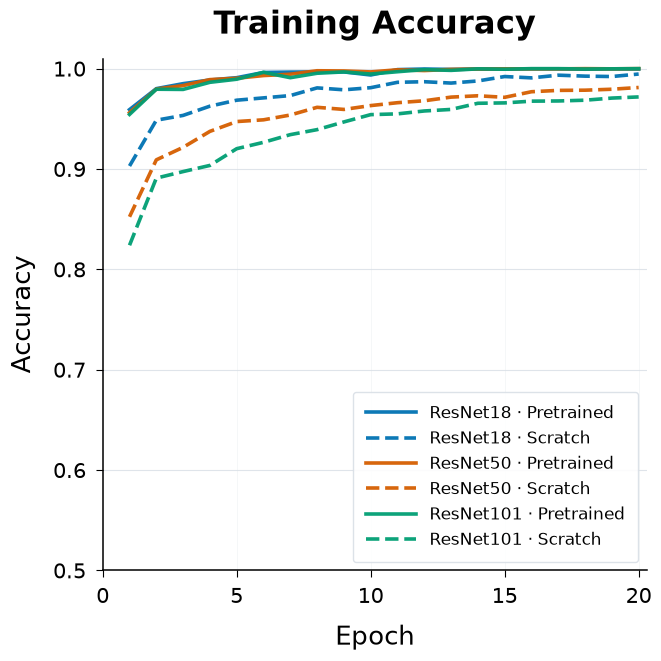

In [11]:
plot_metric("train_accuracy", "Training Accuracy", "Accuracy", "train_accuracy")

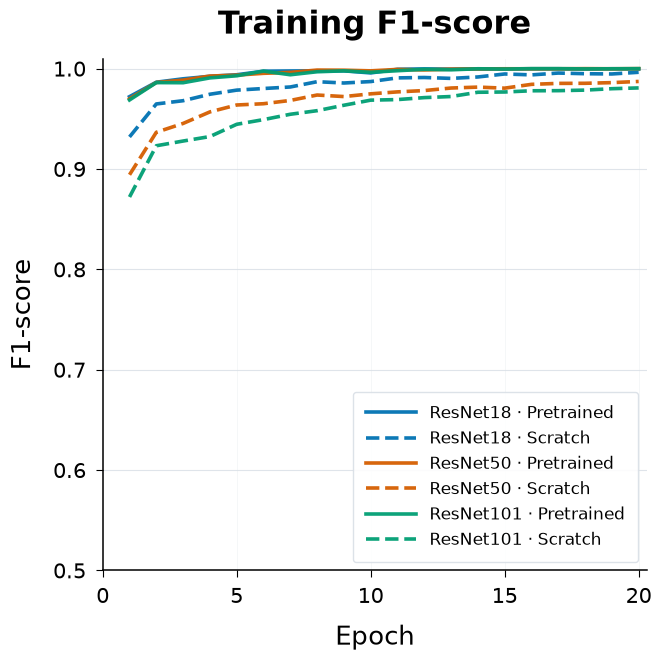

In [12]:
plot_metric("train_f1", "Training F1-score", "F1-score", "train_f1")

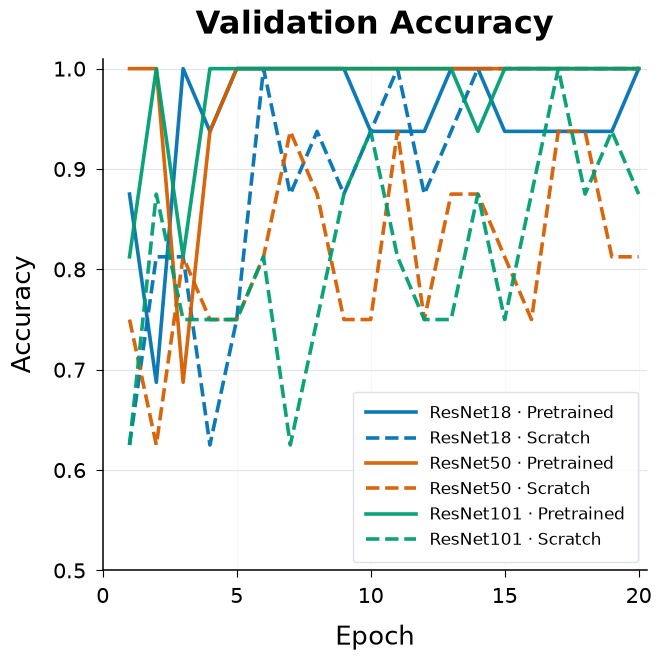

In [13]:
plot_metric("val_accuracy", "Validation Accuracy", "Accuracy", "val_accuracy")

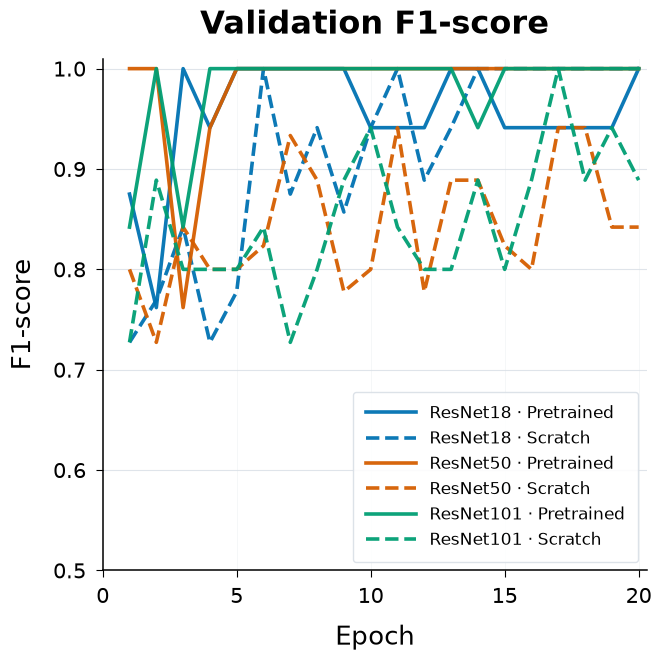

In [14]:
plot_metric("val_f1", "Validation F1-score", "F1-score", "val_f1")

圖形不做平滑，直接呈現 history 原始數值。Y 軸下限固定 0.5，因此低於 0.5 的值不會顯示。
F1 為既有訓練程式記錄的肺炎正類 F1；training 指標來自訓練當下的 augmented batches。
預設另外保存四張 PNG 與四張 PDF 至 `comparison_figures`。
